# Bài 4 – FER2013 CNN

Châu Quốc Bảo – 3123411024. Dùng core của TV1. Xem `data/README_DATA.md` về nguồn, định dạng và giới hạn so sánh. Chỉ tập train của cấu hình augmentation được lật ngang và biến đổi affine. Validation và test giữ nguyên.

Nếu CSV và checkpoint đã tồn tại, notebook hiển thị kết quả đã chạy. Đặt `RETRAIN = True` để huấn luyện lại.


In [1]:
from pathlib import Path
import os
if Path.cwd().name == 'notebooks':
    os.chdir('..')
from src.face_experiment import run, plot_comparison


In [2]:
DATA = Path('data/fer2013.csv')
if not DATA.exists():
    DATA = Path('../BTLON02_Emotion_HoTen_MaSV.zip/data/fer2013.csv')
EPOCHS, BATCH_SIZE, SEED = 30, 128, 42
RETRAIN = False
assert DATA.exists(), 'Hãy chuẩn bị dữ liệu theo data/README_DATA.md'


In [3]:
import csv
result_path = Path('logs/result_04_emotion_baseline.csv')
checkpoint_path = Path('checkpoints/04_emotion_baseline.pt')
if RETRAIN or not result_path.exists() or not checkpoint_path.exists():
    baseline = run('emotion', DATA, 'baseline', epochs=EPOCHS, batch_size=BATCH_SIZE, seed=SEED)
else:
    with result_path.open(encoding="utf-8", newline="") as f:
        baseline = next(csv.DictReader(f))
baseline


{'task': 'emotion',
 'variant': 'baseline',
 'train_count': '28709',
 'val_count': '3589',
 'test_count': '3589',
 'seed': '42',
 'epochs_run': '30',
 'batch_size': '128',
 'initial_lr': '0.001',
 'optimizer': 'Adam',
 'parameters': '2390791',
 'test_loss': '2.994856026352664',
 'test_accuracy': '0.5692393424352187',
 'keras_reference_loss': '1.407',
 'keras_reference_accuracy': '0.5954',
 'seconds': '74.19051861763',
 'device': 'cuda',
 'torch_version': '2.6.0+cu124'}

In [4]:
import csv
result_path = Path('logs/result_04_emotion_augmentation.csv')
checkpoint_path = Path('checkpoints/04_emotion_augmentation.pt')
if RETRAIN or not result_path.exists() or not checkpoint_path.exists():
    improved = run('emotion', DATA, 'augmentation', epochs=EPOCHS, batch_size=BATCH_SIZE, seed=SEED)
else:
    with result_path.open(encoding="utf-8", newline="") as f:
        improved = next(csv.DictReader(f))
improved


{'task': 'emotion',
 'variant': 'augmentation',
 'train_count': '28709',
 'val_count': '3589',
 'test_count': '3589',
 'seed': '42',
 'epochs_run': '30',
 'batch_size': '128',
 'initial_lr': '0.001',
 'optimizer': 'Adam',
 'parameters': '2390791',
 'test_loss': '1.0181766806554915',
 'test_accuracy': '0.6274728336584007',
 'keras_reference_loss': '1.0158',
 'keras_reference_accuracy': '0.6163',
 'seconds': '109.589271068573',
 'device': 'cuda',
 'torch_version': '2.6.0+cu124'}

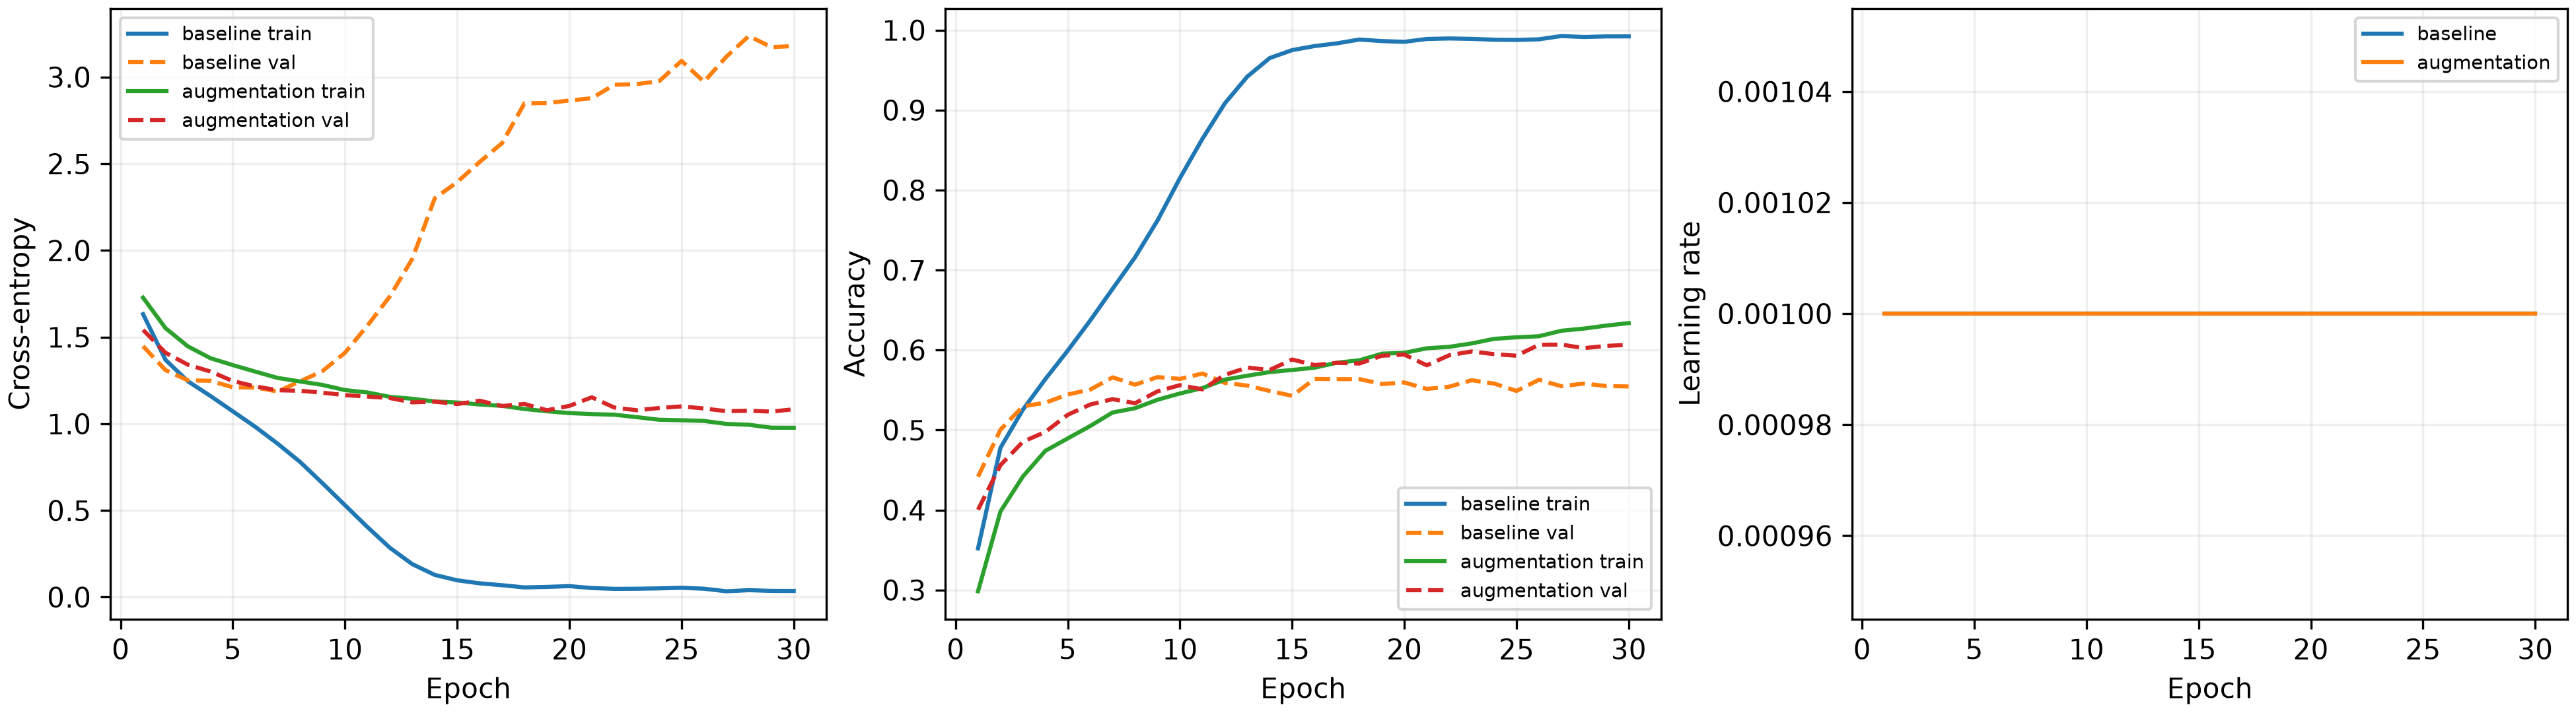

In [5]:
plot_comparison('emotion')
from IPython.display import display, Image
display(Image(filename='figures/04_emotion_before_after_aug.png'))


So sánh các tệp `logs/result_*` và đường cong. Mốc Keras trong slide chỉ để tham khảo; chỉ kết luận về hiệu quả kỹ thuật khi có kết quả chạy thực tế.
